# Flow Inversion on MNIST

Using the trained flows from the noise-variance sweep, we invert the forward pass via `inverse_step` to map real images back to the source distribution $p_0 = \mathcal{N}(0.5, \sigma^2 I)$ and inspect the recovered latent space.

In [1]:
import time

import torch 
from torch import nn, Tensor
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import numpy as np

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

### Load MNIST dataset

In [ ]:


# Normalize pixel values from [0, 1] to [-1, 1] so the data matches a standard
# Gaussian source for flow matching.
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root='../../data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='../../data', train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f'Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}')
images, labels = next(iter(train_loader))
print(f'Batch images shape: {images.shape}, labels shape: {labels.shape}')

Train samples: 60000, Test samples: 10000
Batch images shape: torch.Size([128, 1, 28, 28]), labels shape: torch.Size([128])


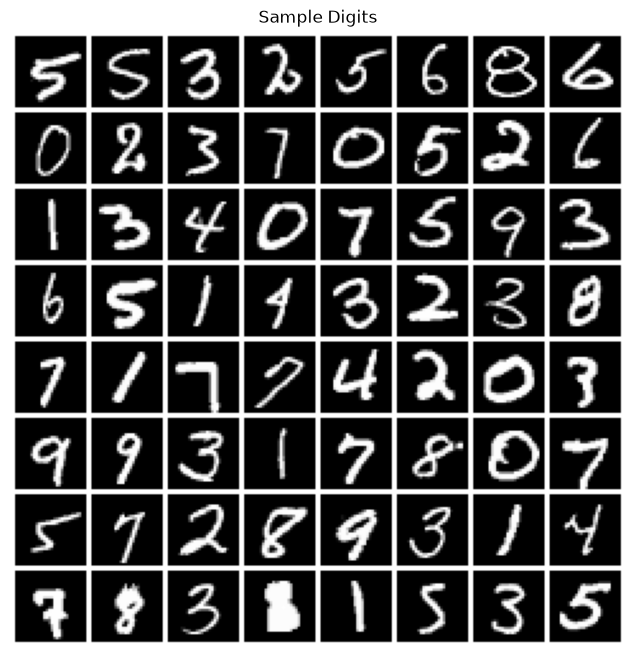

In [4]:
## Display some sample digits

def show_samples(images: Tensor, nrow: int=8, ax=None):
    # images = (images + 1) / 2  # denormalize
    images = images.clamp(0, 1)
    grid = make_grid(images[:nrow**2], nrow, padding=2, pad_value=1)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    ax.set_aspect('equal')
    ax.set_title('Sample Digits')
    ax.imshow(grid.permute(1, 2, 0).cpu())
    ax.axis('off')
    return ax

show_samples(images);

In [12]:
class Flow(nn.Module):

    def __init__(self, dim: int=28*28, h: int=128):
        super().__init__()
        self.dim = dim
        self.h = h

        self.net = nn.Sequential(
            nn.Linear(dim+1, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, h),
            nn.ReLU(),
            nn.Linear(h, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, dim),
        )
    def forward(self, x, t):
        x_t = torch.cat([x, t], dim=1)
        return self.net(x_t)

    def step(self, x_t: Tensor, t_start: float, t_end: float):
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self(x_t + self(x_t, t=t_start)*dt/2, t=(t_start + t_end)/2)

    def inverse_step(self, x_t: Tensor, t_start: float, t_end: float):
        t_end = t_end.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t - dt * self(x_t, t=t_end)



In [13]:
def train_flow(flow, train_loader, n_epochs=50, lr=1e-3, sigma_noise=0.2, device=device):
    losses = []
    opt = torch.optim.Adam(flow.parameters(), lr=lr)
    for e in range(n_epochs):
        current_loss = 0.0
        for i, (x, _) in enumerate(train_loader):
            x_1 = x.view(-1, 784).to(device)

            t = torch.rand(x.shape[0], 1, device=x_1.device)
            x_0 = torch.randn_like(x_1)*sigma_noise + 0.5
            dx_t = x_1 - x_0
            x_t = (1-t)*x_0 + t * x_1
            flow_pred = flow(x_t, t)

            loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
            loss.backward()
            opt.step()
            opt.zero_grad()

            current_loss += loss.item()
        avg_loss = current_loss / len(train_loader)
        losses.append(avg_loss)
        print(f'\r[{100*(e+1)/n_epochs:.0f}%] Epoch {e+1}/{n_epochs}  loss: {avg_loss:.4f}', end='', flush=True)

    return losses

In [14]:
SIGMAS = np.logspace(-2, 0, 6)
sigma_losses = {}
sigma_flows = {}
for sigma in SIGMAS:
    flow = Flow(h=256).to(device)
    losses = train_flow(flow, train_loader, n_epochs=50, lr=1e-3, sigma_noise=sigma, device=device)
    sigma_losses[sigma] = losses
    sigma_flows[sigma] = flow
    print(f'Training completed for sigma={sigma}. Final loss: {losses[-1]:.4f}')



[100%] Epoch 50/50  loss: 7.9499Training completed for sigma=0.01. Final loss: 7.9499
[100%] Epoch 50/50  loss: 8.4774Training completed for sigma=0.025118864315095794. Final loss: 8.4774
[100%] Epoch 50/50  loss: 12.8542Training completed for sigma=0.06309573444801933. Final loss: 12.8542
[100%] Epoch 50/50  loss: 34.1959Training completed for sigma=0.15848931924611143. Final loss: 34.1959
[100%] Epoch 50/50  loss: 138.6580Training completed for sigma=0.3981071705534973. Final loss: 138.6580
[100%] Epoch 50/50  loss: 724.8622Training completed for sigma=1.0. Final loss: 724.8622


### Flow inversion

sigma=0.010: inverted 60000 train images
sigma=0.025: inverted 60000 train images
sigma=0.063: inverted 60000 train images
sigma=0.158: inverted 60000 train images
sigma=0.398: inverted 60000 train images
sigma=1.000: inverted 60000 train images


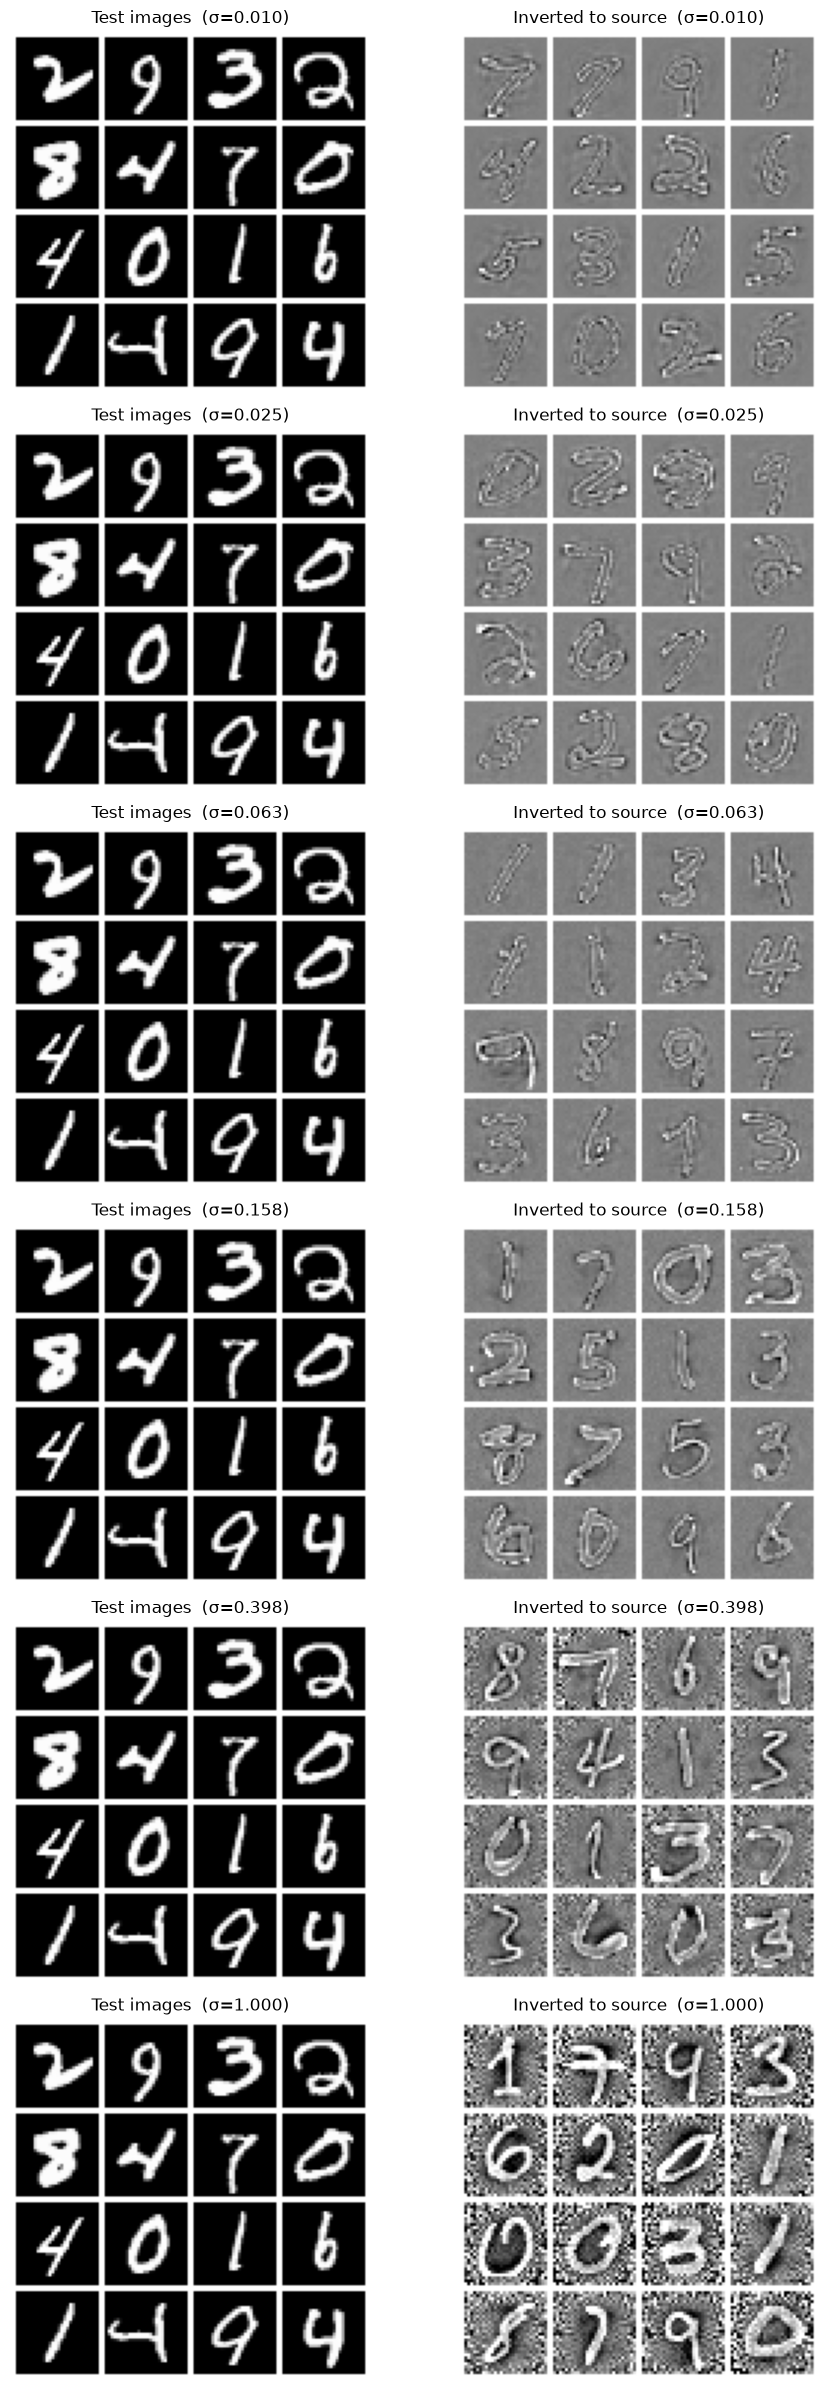

In [19]:
sigmas = list(sigma_flows.keys())

n_steps = 50
# inverse_step(x, t_start, t_end) undoes the forward step from t_start→t_end,
# so we iterate the same linspace(0,1) in reverse order.
time_steps = torch.linspace(0.0, 1.0, n_steps + 1)

sigma_inverted = {}
sigma_labels = {}
for sigma in sigmas:
    model = sigma_flows[sigma]
    all_inverted = []
    labels = []

    with torch.no_grad():
        for x_batch, l_batch in train_loader:
            x = x_batch.view(-1, 784).to(device)
            for j in reversed(range(n_steps)):
                x = model.inverse_step(x_t=x, t_start=time_steps[j].to(device), t_end=time_steps[j + 1].to(device))
            all_inverted.append(x.cpu())
            labels.append(l_batch)

    sigma_inverted[sigma] = torch.cat(all_inverted, dim=0)
    sigma_labels[sigma] = torch.cat(labels, dim=0)
    print(f'sigma={sigma:.3f}: inverted {sigma_inverted[sigma].shape[0]} train images')

# Display first 16 test images alongside their inversions
train_images_display, _ = next(iter(train_loader))
x_1_display = train_images_display[:16].view(-1, 1, 28, 28)

fig, axes = plt.subplots(len(sigmas), 2, figsize=(10, 4 * len(sigmas)), squeeze=False)

for i, sigma in enumerate(sigmas):
    show_samples(x_1_display, nrow=4, ax=axes[i, 0])
    axes[i, 0].set_title(f'Test images  (σ={sigma:.3f})')

    show_samples(sigma_inverted[sigma][:16].view(-1, 1, 28, 28), nrow=4, ax=axes[i, 1])
    axes[i, 1].set_title(f'Inverted to source  (σ={sigma:.3f})')

plt.tight_layout()
plt.show()

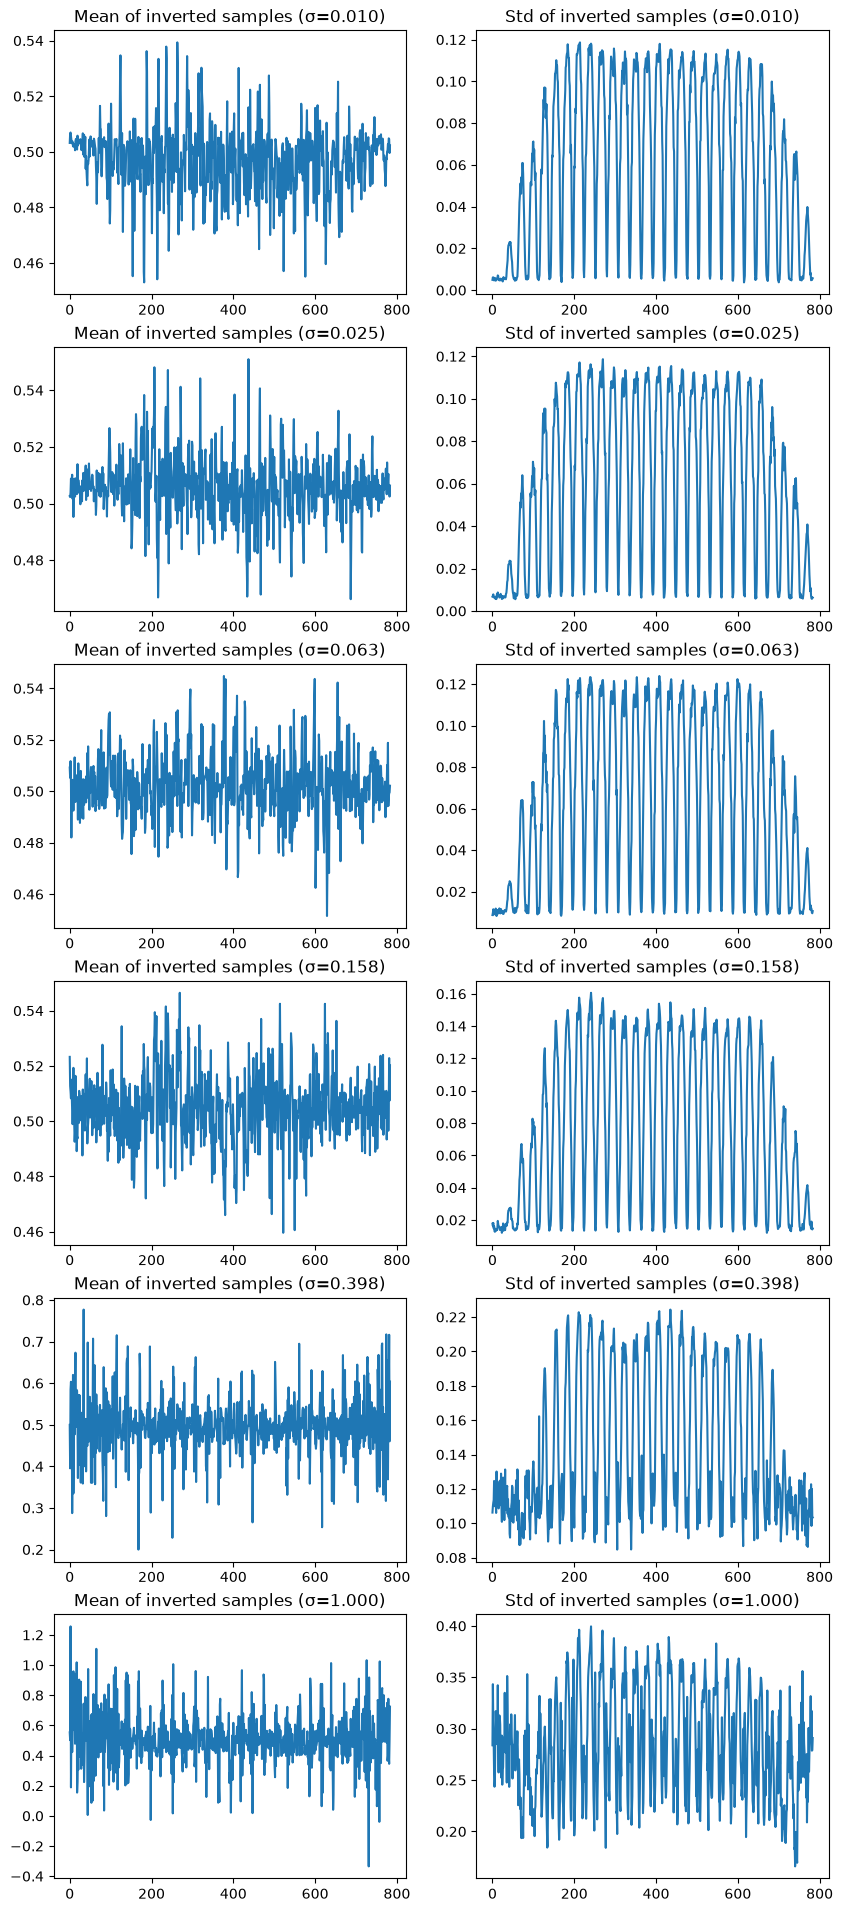

In [20]:
# Compute statistics of the inverted samples per channel for each sigma.

mu_channel = sigma_inverted[sigma].mean(dim=0)
sigma_channel = sigma_inverted[sigma].std(dim=0)

fig, axes = plt.subplots(len(sigmas), 2, figsize=(10, 4 * len(sigmas)), squeeze=False)
for i, sigma in enumerate(sigmas):
    mu_channel = sigma_inverted[sigma].mean(dim=0)
    sigma_channel = sigma_inverted[sigma].std(dim=0)

    axes[i, 0].plot(mu_channel.cpu().numpy())
    axes[i, 0].set_title(f'Mean of inverted samples (σ={sigma:.3f})')

    axes[i, 1].plot(sigma_channel.cpu().numpy())
    axes[i, 1].set_title(f'Std of inverted samples (σ={sigma:.3f})')

sigma=0.010: inverted 10000 test images
sigma=0.025: inverted 10000 test images
sigma=0.063: inverted 10000 test images
sigma=0.158: inverted 10000 test images
sigma=0.398: inverted 10000 test images
sigma=1.000: inverted 10000 test images


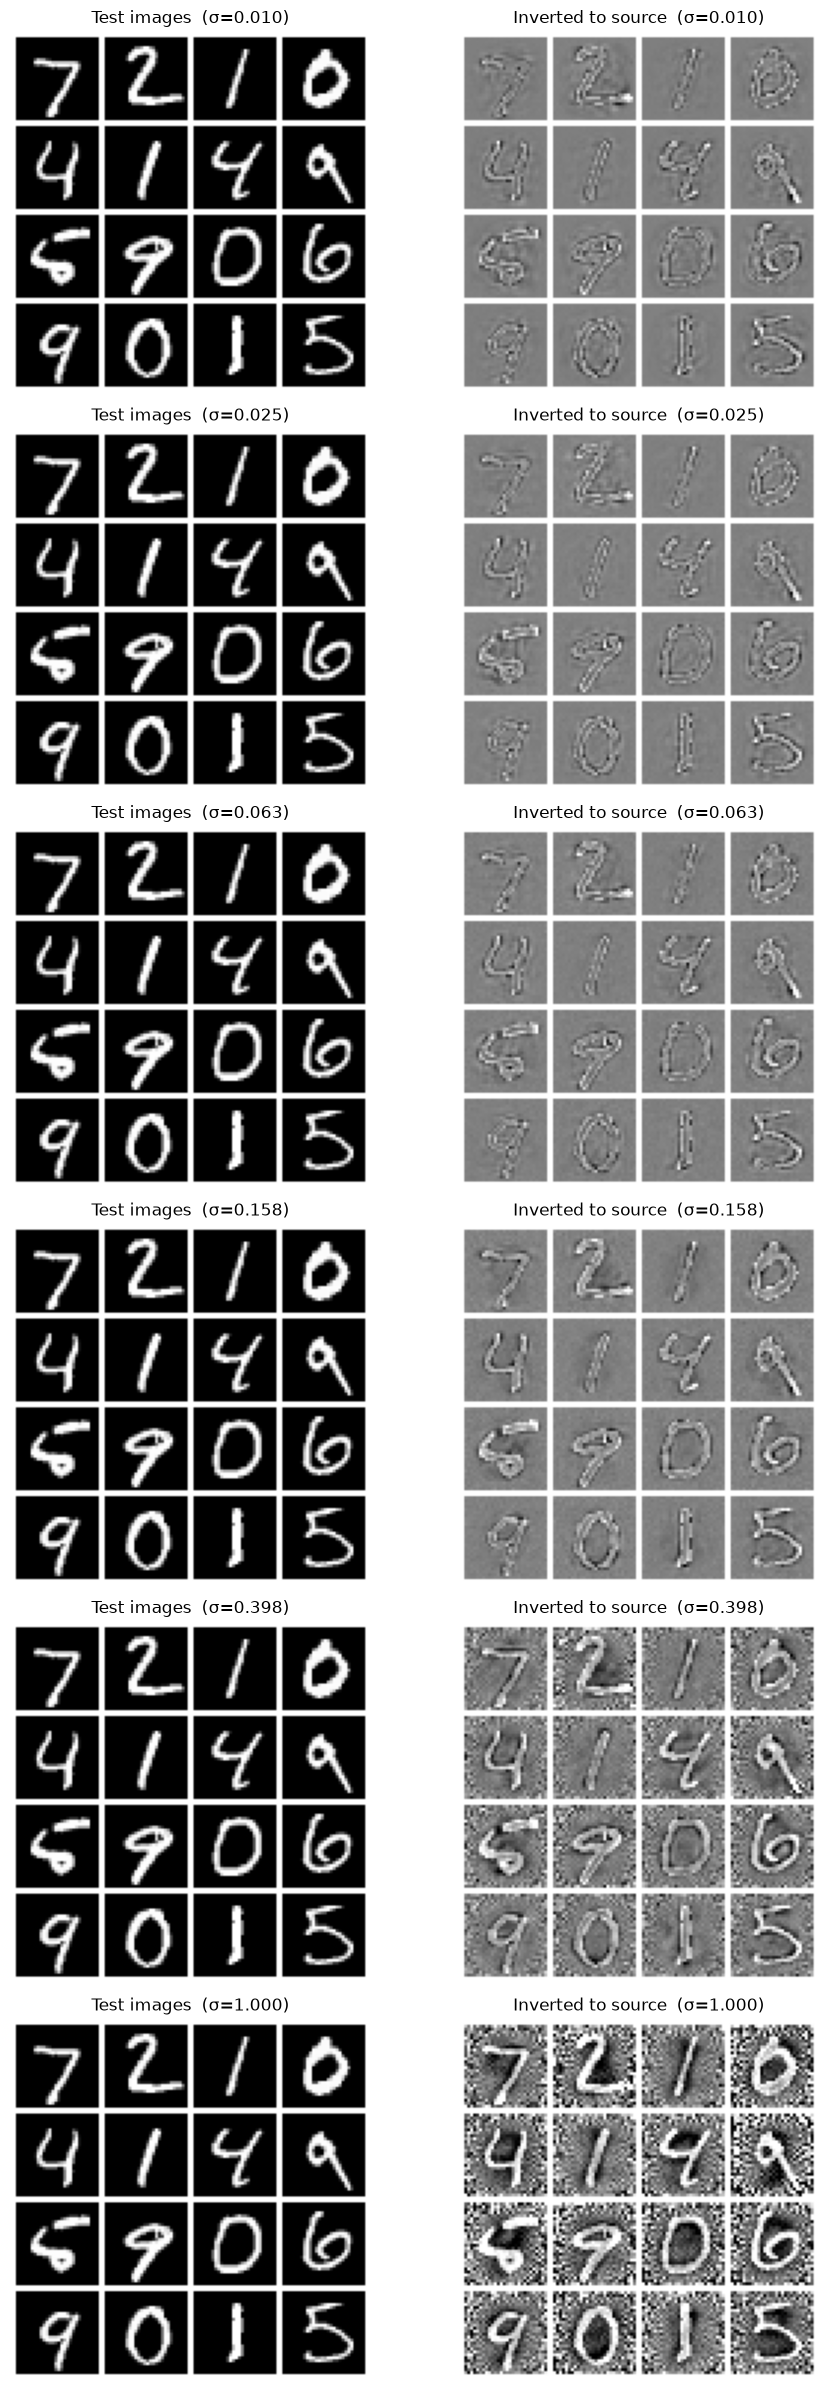

In [21]:
# Compute reverse samples using the inverse_step method from the test dataset using the models with intermediate values of sigma.


n_steps = 100
# inverse_step(x, t_start, t_end) undoes the forward step from t_start→t_end,
# so we iterate the same linspace(0,1) in reverse order.
time_steps = torch.linspace(0.0, 1.0, n_steps + 1)

sigma_inverted_test = {}
for sigma in sigmas:
    model = sigma_flows[sigma]
    all_inverted = []

    with torch.no_grad():
        for x_batch, _ in test_loader:
            x = x_batch.view(-1, 784).to(device)
            for j in reversed(range(n_steps)):
                x = model.inverse_step(x_t=x, t_start=time_steps[j].to(device), t_end=time_steps[j + 1].to(device))
            all_inverted.append(x.cpu())

    sigma_inverted_test[sigma] = torch.cat(all_inverted, dim=0)
    print(f'sigma={sigma:.3f}: inverted {sigma_inverted_test[sigma].shape[0]} test images')

# Display first 16 test images alongside their inversions
test_images_display, _ = next(iter(test_loader))
x_1_display = test_images_display[:16].view(-1, 1, 28, 28)

fig, axes = plt.subplots(len(sigmas), 2, figsize=(10, 4 * len(sigmas)), squeeze=False)

for i, sigma in enumerate(sigmas):
    show_samples(x_1_display, nrow=4, ax=axes[i, 0])
    axes[i, 0].set_title(f'Test images  (σ={sigma:.3f})')

    show_samples(sigma_inverted_test[sigma][:16].view(-1, 1, 28, 28), nrow=4, ax=axes[i, 1])
    axes[i, 1].set_title(f'Inverted to source  (σ={sigma:.3f})')

plt.tight_layout()
plt.show()


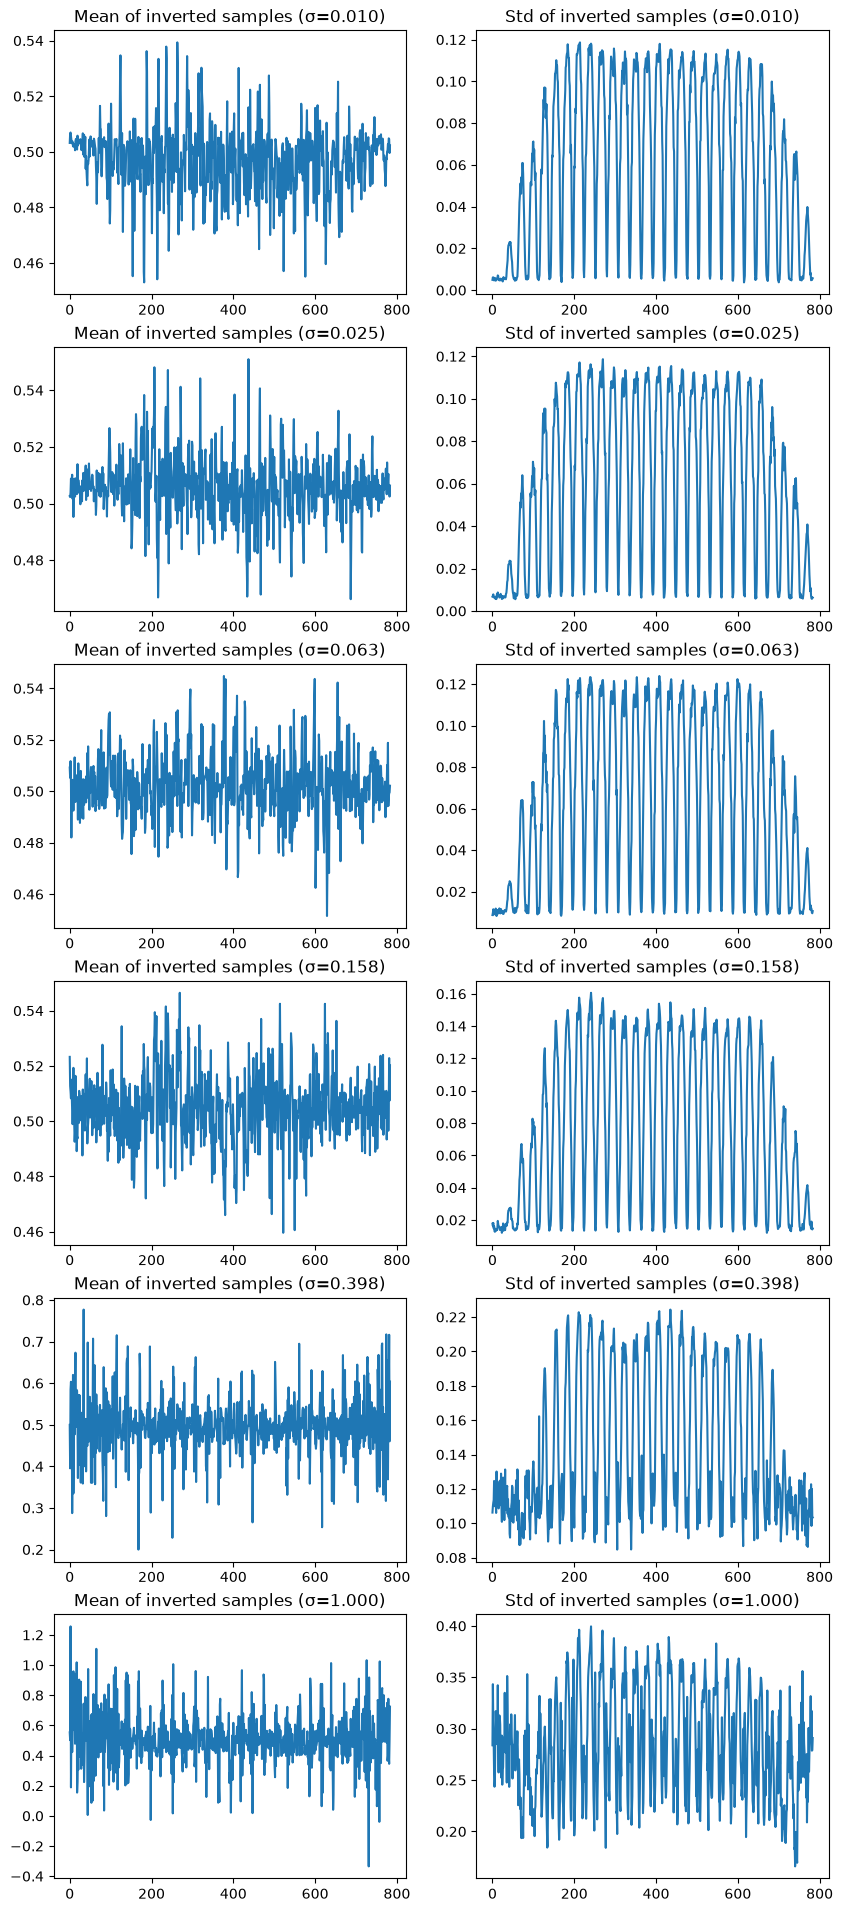

In [23]:
# Compute statistics of the inverted samples per channel for each sigma.

mu_channel = sigma_inverted[sigma].mean(dim=0)
sigma_channel = sigma_inverted[sigma].std(dim=0)

fig, axes = plt.subplots(len(sigmas), 2, figsize=(10, 4 * len(sigmas)), squeeze=False)
for i, sigma in enumerate(sigmas):
    mu_channel = sigma_inverted[sigma].mean(dim=0)
    sigma_channel = sigma_inverted[sigma].std(dim=0)

    axes[i, 0].plot(mu_channel.cpu().numpy())
    axes[i, 0].set_title(f'Mean of inverted samples (σ={sigma:.3f})')

    axes[i, 1].plot(sigma_channel.cpu().numpy())
    axes[i, 1].set_title(f'Std of inverted samples (σ={sigma:.3f})')
